## Classification

Classification $y_i \in \{1, ... , K\}$- $K$ classes

Example of multiclass ($K \ge 3$) classification task:


*   Classify images (what is on the picture?)


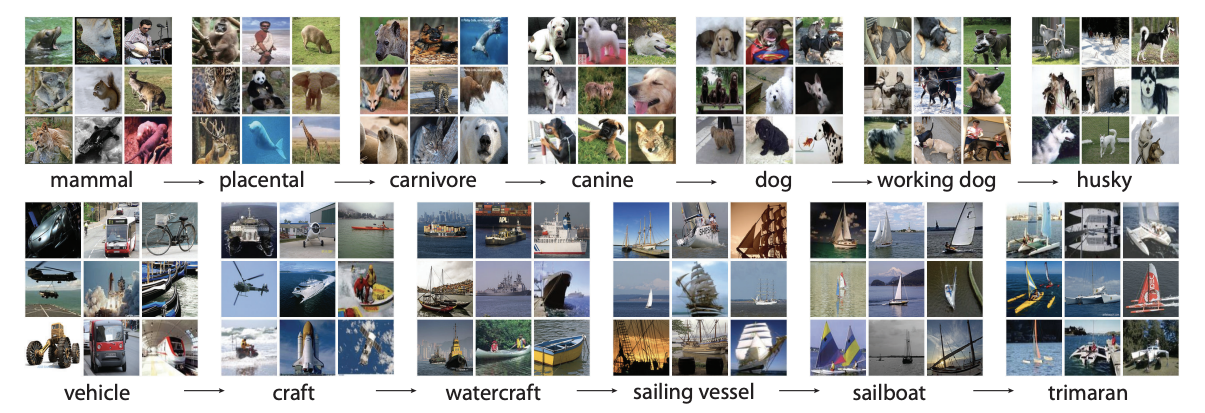

*   Classify texts by topic (travel, comedy, business, ...)
*   [Air quality of the region](https://www.kaggle.com/datasets/mujtabamatin/air-quality-and-pollution-assessment) (good/ok/bad/hazardous?)
*   [Stress level](https://www.kaggle.com/datasets/poushal02/student-academic-stress-real-world-dataset) (no sress/some stress/a lot of stress)


Binary classification - 2 classes (often $y_i \in \{ -1, +1\}$ or $y_i \in \{ 0, +1\}$)

Examples:


*   [Does post contain mention of a disaster?](https://www.kaggle.com/datasets/vstepanenko/disaster-tweets)
* [Does the student have depression?](https://www.kaggle.com/datasets/hopesb/student-depression-dataset)
*  [Are news fake?](https://www.kaggle.com/datasets/evilspirit05/bengali-fake-news-dataset)


## Logistic regression

### Theory

 We'll solve the binary classification problem by predicting the probability that an object belongs to the positive (+1) class.

 Suppose we have a linear model of the form:

 $$a(x) = w_0 + w_1x_1 + w_2x_2 + ... + w_d x_d = w_0 + \sum_{i=1}^d w_ix_i$$



**Question:** can we use $a(x)$ as a probability of a positive class?

To get  probability we use sigmoid or logistic function.

$$\sigma(x)=\frac{1}{1+e^{−x}}$$

It looks like this:

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/8/88/Logistic-curve.svg/1200px-Logistic-curve.svg.png" width="500" height="300">

And knowing the probabilities ($p=\sigma(a(x))$), we will ultimately be able to say whether the object belongs to class 0 or +1.

For example, we can consider that if the probability of belonging to the positive class is greater than 0.5 ($p>0.5$), the object is classified as positive class (+1), otherwise, negative class (0).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Practise

Let's use [Iris dataset](https://en.wikipedia.org/wiki/Iris_flower_data_set)

This dataset consists of 150 observations, each of which represents four measurements: `sepal length`, `sepal width`, `petal length`, and `petal width`. Each observation belongs to one of three iris classes: setosa, versicolor, or virginica.

The task is to predict the flower class based on the measurements.

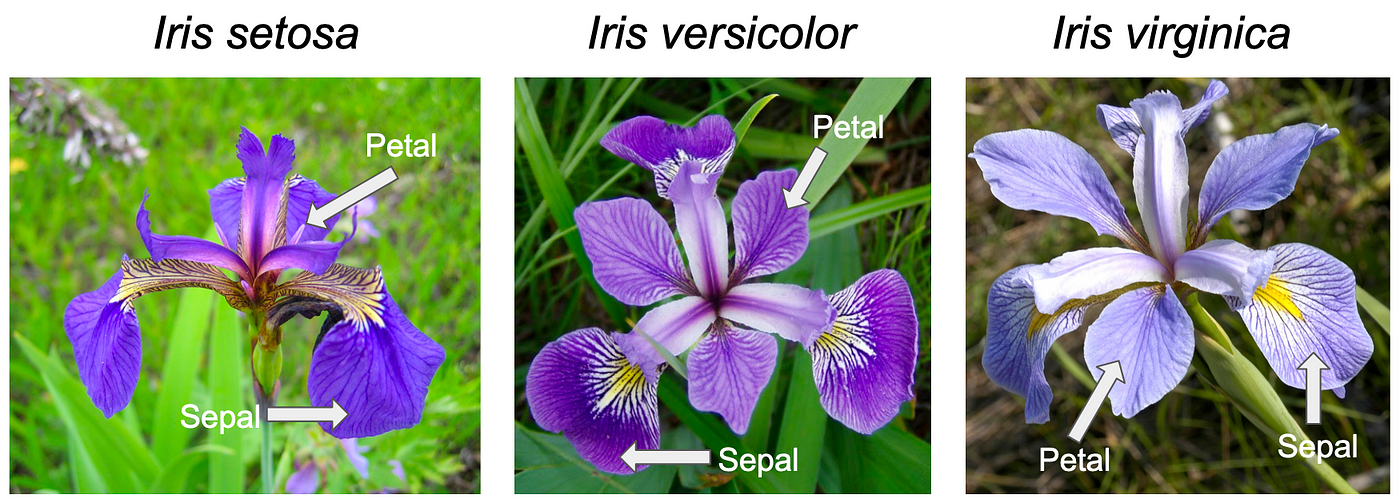

In [ ]:
from sklearn.datasets import load_iris
data = load_iris()
X = pd.DataFrame(data['data'], columns = data['feature_names'])
y = data['target'].copy()
X.head()

In [ ]:
np.unique(y, return_counts=True)

In [ ]:
data['target_names']

Let's make the classification binary: we will predict if the flower is versicolor or not.

So versicolor (class 1) will be +1 and setosa, virginica (classes 0, 2) will be 0.

**Task** Change the target vector `y`

In [ ]:
y[y == 2] = 0
y

In [ ]:
assert np.allclose(np.unique(y, return_counts=True), (np.array([0, 1]), np.array([100,  50])))

np.unique(y, return_counts=True)

Also, let's work only with 2 features (so it would be possible to plot)

**Task** choose the features`sepal length (cm)` and `sepal width (cm)`

In [ ]:
X = X[['sepal length (cm)', 'sepal width (cm)']]
X

Let's split the data into train and test sets.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state=0)

In [ ]:
np.unique(y_train, return_counts=True)

In [ ]:
np.unique(y_test, return_counts=True)

In [ ]:
y_test

In [ ]:
plt.title('Train points colored by target')

#color is the target: purple (0) and yellow (1)
plt.scatter(X_train['sepal length (cm)'],
            X_train['sepal width (cm)'],
            c = y_train);

Note: selecting train/test randomly is important. Why? - order of the samples will not break our pipeline:

What if we just decided to take the last 30\% of samples as test?

In [ ]:
##THIS IS BAD CODE, DO NOT USE IT FOR TRAIN-TEST SELECTION##
X_train_bad = X[:-int(len(X) * 0.3)]
X_test_bad = X[-int(len(X) * 0.3):]
y_train_bad = y[:-int(len(X) * 0.3)]
y_test_bad = y[-int(len(X) * 0.3):]

In [ ]:
y_test_bad

In [ ]:
y_test



Split data in train and test carefully!

Let's fit logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

lr.fit(X_train, y_train)

Now, we can predict:

In [ ]:
lr.predict(X_train)

In [ ]:
plt.title('Train points colored by prediction of the model')
#color is the prediction: purple (0) and yellow (1)
plt.scatter(X_train['sepal length (cm)'],
            X_train['sepal width (cm)'],
            c = lr.predict(X_train))

It is possible to get the probabilities:

In [ ]:
lr.predict_proba(X_train)[:10]

We also can see the coefficients and intercept:

In [ ]:
lr.intercept_, lr.coef_

Let's try to apply manually:

For example, we have a sample with `sepal length (cm)` = 6, `sepal width (cm)` = 3

In [ ]:
w_0 = lr.intercept_[0]
w_1, w_2 = lr.coef_[0]

Compute $a(x) = w_0 + w_1x_1 + w_2x_2$, where $x_1$ - sepal length (cm) $x_2$ - sepal width (cm)

In [ ]:
a = w_0 + w_1 * 6 + w_2 * 3
a

In [ ]:
#this value can be computed using sklearn
lr.decision_function([[6.0, 3.0]])

Now, apply the $\sigma$, to get the probability $p$ of class 1:

In [ ]:
def sigmoid(x):
  return 1 / (1 + np.exp(-x))

p = sigmoid(a)
p

And the probability of class 0 is $1 - p$

In [ ]:
1 - p

The same using sklearn: first column - the probability of class 0, second - probability of class 1.

In [ ]:
lr.predict_proba([[6.0, 3.0]])

And the final prediction is 1 if $p > 0.5$ and 0 otherwise

In [ ]:
int(p > 0.5)

Using sklearn:

In [ ]:
lr.predict([[6.0, 3.0]])

In the end, the sample should be classified as class 0 (the probability of it being class 0 is estimated as around 0.7)

### Plotting

Let's visualize the model. But how?

In linear regression $y = w_0 + w_1 x_1 + w_2 x_2$ (if there are 2 features)

In logistic regression $y = \sigma(w_0 + w_1 x_1 + w_2 x_2) = \frac{1}{e^{-(w_0 + w_1 x_1 + w_2 x_2)}}$

That seems hard, however to visualize the model we do not need to work with $\sigma()$. Why? - Because $\sigma()$ just gives the probability.

If $x>0 \Rightarrow \sigma(x) > 0.5$ - class 1

If $x=0 \Rightarrow \sigma(x) = 0.5$ - unsure

If $x<0 \Rightarrow \sigma(x) < 0.5$ - class 0

So, if we draw the points, where model is unsure - we will draw the curve that separates the classes (if the point is not on the curve - the class is known)

So, we need to solve $w_0 + w_1 x_1 + w_2 x_2 = 0$

Answer:

$x_2 = -\frac{w_0 + w_1 x_1}{w_2}$

This is a straight line.


In [ ]:
#generate x1
x_1 = np.arange(X_train['sepal length (cm)'].min(), X_train['sepal length (cm)'].max()+0.2, 0.05)
#calculate x2
x_2 = -(w_0 + x_1 * w_1) / w_2

In [ ]:
plt.plot(x_1, x_2);

Adding train/tet data

In [ ]:
fig, axs = plt.subplots(ncols=2, figsize=(10, 6))
axs[0].set_title('Train points colored by target and model')
axs[1].set_title('Train points colored by prediction and model')

axs[0].scatter(X_train['sepal length (cm)'], X_train['sepal width (cm)'], c = y_train)
axs[1].scatter(X_train['sepal length (cm)'], X_train['sepal width (cm)'], c = lr.predict(X_train))

axs[0].plot(x_1, x_2)
axs[1].plot(x_1, x_2)

And for the test set:

In [ ]:
fig, axs = plt.subplots(ncols=2, figsize=(10, 6))
axs[0].set_title('Test points colored by target and model')
axs[1].set_title('Test points colored by prediction and model')

axs[0].scatter(X_test['sepal length (cm)'], X_test['sepal width (cm)'], c = y_test)
axs[1].scatter(X_test['sepal length (cm)'], X_test['sepal width (cm)'], c = lr.predict(X_test))

axs[0].plot(x_1, x_2)
axs[1].plot(x_1, x_2)

Actually, for easier plotting we can use special function:

In [ ]:
#!pip install mlxtend

In [ ]:
from mlxtend.plotting import plot_decision_regions

In [ ]:
#Train
plot_decision_regions(X_train.values,
                      y_train,
                      clf=lr)

In [ ]:
#Test
plot_decision_regions(X_test.values,
                      y_test,
                      clf=lr)

### Hyperparameters

We also have hyperparameters for logistic regression.

For example, we also can apply regularization and we have $\alpha$ - the strength of it.

However! In sklearn [LogisticRegression](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html) there is no `alpha`, but there is 'C': inverse of regularization strength ($C = \frac{1}{\alpha}$). So the smaller C, the stronger is the regularization.


In [ ]:
C_list = [0.1, 0.5, 10]

fig, axs = plt.subplots(ncols=3, figsize=(12, 8))

for ii, C in enumerate(C_list):
    clf = LogisticRegression(C=C)
    clf.fit(X_train.values, y_train)


    plot_decision_regions(X_train.values, y_train, clf=clf, legend=2, ax=axs[ii])
    axs[ii].set_title('C='+str(C))

We can see that the model differ if we change C.

We need to tune it. Same approaches (validation set, cross-validation) can be used

To assess the model (and to search for hyperparameters) we need to use the quality metrics

## Quality metrics (for beginners)

Error rate:

$$\frac{1}{N} \sum_{i=1}^N I[y_i \neq \hat{y}_i]$$

From 0 to 1, closer to 0 - better

Accuracy:

$$\frac{1}{N} \sum_{i=1}^N I[y_i = \hat{y}_i]$$


From 0 to 1, closer to 1 - better

In [ ]:
from sklearn.metrics import accuracy_score

print('Train accuracy =', accuracy_score(y_train, lr.predict(X_train)))
print('Test  accuracy =', accuracy_score(y_test,  lr.predict(X_test)))

What san be said: on the new data our model classify 64\% of samples correctly

**Question** what will be the accuracy of random classifier? (with probability 0.5 gives class 0 and with probability 0.5 gives class 1)

**Task** Create a random classifier and compute the accuracy

In [ ]:
#your code here
y_pred_random = np.random.choice([0, 1], size=len(y_test))
accuracy_score(y_test,  y_pred_random)

In [ ]:
accuracy_score(y_test,  y_pred_random)

## Hyperparameter tuning using cross-validation

We need to search for best hyperparameter $C$, we can divide into train, validation and test.


Problem with separate validation set: shrink the amount data to use for training.

Idea: let's split the data into $n$ folds of similar size and train the model $n$ times, each time - one fold is validation and other $n-1$ is trin set. Compute loss $n$ times and take average.

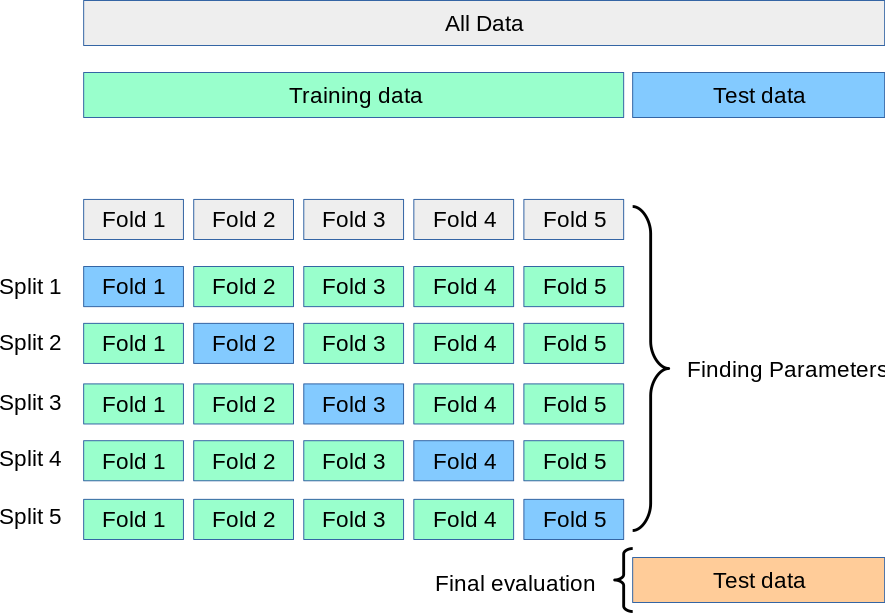

Cross-validation is useful for hyperparameter search: for every set of hyperparameters apply cross-validation and compute the quality. Choose the model with the best quality

In [ ]:
from sklearn.model_selection import GridSearchCV

params = {'C' : np.logspace(-5, 2, 100)
         }

clf = GridSearchCV(LogisticRegression(), params,
                   cv=5, scoring='accuracy',
                   verbose=5 #how much info we want to see
                   )
clf.fit(X_train, y_train)

We can check the best hyperparameters:

In [ ]:
clf.best_params_

Or just use the fitted `GridSearchCV` object. The best model is saved there.

In [ ]:
accuracy_score(y_test,  clf.predict(X_test))

In [ ]:
clf.predict(X_test)

## Quality metrics



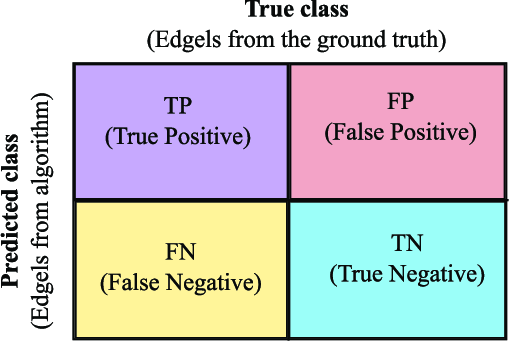

**Task** Compute accuracy based on confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix

def accuracy(y, p):
    (TN, FP), (FN, TP) = confusion_matrix(y, p)
    return (TP + TN) / (TN + FP + FN + TP)

In [ ]:
accuracy(y_test,  clf.predict(X_test))

There are other metrics:

* Precision is the fraction of correctly classified as class 1 among the all classified as class 1 objects (Idea: how precise is our prediction? How often we are correct about our 1 prediction?)

* Recall is the fraction of correctly classified as class 1 among the all class 1 objects (Idea: how much of the class 1 we can acutally detect?)

Precision and recall are from 0 to 1 (closer to 1 the better).

**Task** Compute precision and recall

In [ ]:
def precision(y, p):
    (TN, FP), (FN, TP) = confusion_matrix(y, p)

    return  #your code here

def recall(y, p):
    (TN, FP), (FN, TP) = confusion_matrix(y, p)

    return  #your code here

In [ ]:
precision(y_test,  clf.predict(X_test))

There is precision in sklearn library. If we cannot compute it, it will be 0

In [ ]:
from sklearn.metrics import precision_score

precision_score(y_test,  clf.predict(X_test))

In [ ]:
recall(y_test,  clf.predict(X_test))

In [ ]:
from sklearn.metrics import recall_score

recall_score(y_test,  clf.predict(X_test))

We can combine them using F-score = $(2\times precision \times recall)/ (precision + recall)$

**Task** Compute F1-score

In [ ]:
def f1(y, p):
    pr = precision(y, p)
    rec = recall(y, p)
    return #your code here

In [ ]:
f1(y_test,  clf.predict(X_test))

In [ ]:
from sklearn.metrics import f1_score

f1_score(y_test,  clf.predict(X_test))

Let's compute metrics for our classifiers:

In [ ]:
metric_dict = {"Accuracy": accuracy,
               "Precision": precision,
               "Recall": recall,
               "F1-score": f1}

for title, func in metric_dict.items():
    print(title, func(y_test,  clf.predict(X_test)))


Let's search for hyperparameters again, now assess models with F1-score

In [ ]:
clf = GridSearchCV(LogisticRegression(), params,
                   cv=5, scoring='f1'
                   )
clf.fit(X_train, y_train)


for title, func in metric_dict.items():
    print(title, func(y_test,  clf.predict(X_test)))

The results seems to be setter

How can we improve the model:



*   Feature engineering (f.e. add polynominal features)
*   Try other models
*   [Not always possible] Add more features


The task is hard right now because we chose only 2 features, let's use all 4 features.

In [ ]:
X = pd.DataFrame(data['data'], columns = data['feature_names'])

t = y.copy()
t[t == 2] = 0
X_train, X_test, y_train, y_test = train_test_split(X, t, test_size = 0.3, random_state=10)


clf = GridSearchCV(LogisticRegression(), params,
                   cv=5, scoring='f1'
                   )
clf.fit(X_train, y_train)


for title, func in metric_dict.items():
    print(title, func(y_test,  clf.predict(X_test)))